# Pregunta 2 — Mapeo de inundaciones con Sentinel-1 (U-Net) · Sen1Floods11
**Redes Neuronales y Aprendizaje Profundo · Examen Parcial UNI FIIS 2026-II**

Notebook listo para **Google Colab** (GPU: *Entorno de ejecución → Cambiar tipo → T4*). Ejecuta las celdas **en orden**. No requiere autenticación de Google: el bucket `sen1floods11` es público y se descarga por HTTPS.

| Entregable | Sección |
|---|---|
| 1. U-Net propia en PyTorch (VV, VH) | §3 |
| 2. Ablación: (a) dorada vs. dorada+débil, (b) pérdida, (c) saltos/profundidad | §5 |
| 3. Evaluación en distribución (IoU, F1, precisión, recall, matriz de confusión) | §6 |
| 4. Generalización geográfica (Bolivia) + hipótesis | §7 |
| 5. Análisis cualitativo de fallos SAR | §8 |
| 6. Bono: fusión SAR + Sentinel-2 | §9 |

**Decisiones de diseño clave (justificadas en el informe):**
* Partición oficial: `flood_train/valid/test_data.csv` **no contienen Bolivia**; los 15 chips dorados de Bolivia son el test geográfico. Por tanto el **mismo modelo** entrenado con la partición oficial sirve para el punto 3 (test: eventos vistos) y el punto 4 (Bolivia: región no vista).
* **Selección de modelos solo con el conjunto de validación**. Bolivia y test nunca se usan para elegir hiperparámetros.
* Los chips débiles de Bolivia se **excluyen** del entrenamiento (evita fuga de información geográfica).
* Los píxeles con `-1` (sin dato) y los NaN se **ignoran** en la pérdida y en las métricas.

## §0. Configuración

In [ ]:
FAST_MODE = False   # True = prueba rápida de humo (pocos pasos, pocos chips débiles). False = corrida real.

CFG = dict(
    DATA_DIR='/content/sen1floods11',
    OUT_DIR='/content/outputs',
    SEEDS=[0],              # ej. [0,1,2] para media±desv. (3x más tiempo)
    CROP=256, BATCH=8, LR=1e-3, WD=1e-4,
    ITERS=1500,             # pasos por corrida de ablación
    PRE_ITERS=2500, FT_ITERS=800, FT_LR=2e-4,   # estrategia "pre-entrenar con débiles -> afinar con doradas"
    EVAL_EVERY=100,
    N_WEAK=1500,            # nº de chips débiles a descargar/usar (0 = ninguno; ~4,300 disponibles sin Bolivia)
    WEAK_FRAC=0.5,          # fracción de cada batch que viene de chips débiles en la mezcla
    BASE=32,                # canales base de la U-Net
    DOWNLOAD_S2=True,       # necesario para §8 (RGB) y §9 (bono). ~3 GB
)
if FAST_MODE:
    CFG.update(ITERS=40, PRE_ITERS=40, FT_ITERS=20, EVAL_EVERY=20, N_WEAK=40, BASE=16)
print(CFG)

{'DATA_DIR': '/content/sen1floods11', 'OUT_DIR': '/content/outputs', 'SEEDS': [0], 'CROP': 256, 'BATCH': 8, 'LR': 0.001, 'WD': 0.0001, 'ITERS': 1500, 'PRE_ITERS': 2500, 'FT_ITERS': 800, 'FT_LR': 0.0002, 'EVAL_EVERY': 100, 'N_WEAK': 1500, 'WEAK_FRAC': 0.5, 'BASE': 32, 'DOWNLOAD_S2': True}


In [ ]:
import os, re, json, random, time, math, warnings, subprocess, sys
from concurrent.futures import ThreadPoolExecutor
warnings.filterwarnings('ignore')
try:
    import rasterio
except ImportError:
    subprocess.run([sys.executable,'-m','pip','install','-q','rasterio'],check=True); import rasterio
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset, WeightedRandomSampler
from scipy import ndimage
from scipy.stats import wasserstein_distance
from tqdm.auto import tqdm

DATA_DIR, OUT_DIR = CFG['DATA_DIR'], CFG['OUT_DIR']
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = DEVICE == 'cuda'
print('Device:', DEVICE, '| torch', torch.__version__)
if DEVICE == 'cpu': print('AVISO: sin GPU. Activa GPU en Colab o usa FAST_MODE=True.')

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(42)

Device: cuda | torch 2.11.0+cu130


## §1. Descarga de datos (bucket público `gs://sen1floods11`, v1.1)
Se descargan por HTTPS: splits oficiales, chips dorados (S1, S2, etiqueta manual y etiqueta Otsu-S1 de los mismos chips) y una muestra de chips con etiqueta débil de Sentinel-1 (`S1OtsuLabelWeak`).

In [ ]:
BUCKET, ROOT = 'sen1floods11', 'v1.1'
HAND, WEAK, SPL = f'{ROOT}/data/flood_events/HandLabeled', f'{ROOT}/data/flood_events/WeaklyLabeled', f'{ROOT}/splits/flood_handlabeled'

def gcs_list(prefix):
    out, token = [], None
    while True:
        params = {'prefix': prefix, 'maxResults': 1000}
        if token: params['pageToken'] = token
        r = requests.get(f'https://storage.googleapis.com/storage/v1/b/{BUCKET}/o', params=params, timeout=60)
        r.raise_for_status(); j = r.json()
        out += [it['name'] for it in j.get('items', [])]
        token = j.get('nextPageToken')
        if not token: break
    return out

def local_of(obj): return os.path.join(DATA_DIR, obj[len(ROOT)+1:])

def gcs_download(obj):
    dest = local_of(obj)
    if os.path.exists(dest) and os.path.getsize(dest) > 0: return True
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    url = f'https://storage.googleapis.com/{BUCKET}/{obj}'
    for t in range(4):
        try:
            with requests.get(url, stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(dest + '.part', 'wb') as f:
                    for ch in r.iter_content(1 << 20): f.write(ch)
            os.replace(dest + '.part', dest); return True
        except Exception:
            time.sleep(2 * (t + 1))
    return False

def download_many(objs, desc, workers=16):
    with ThreadPoolExecutor(workers) as ex:
        res = list(tqdm(ex.map(gcs_download, objs), total=len(objs), desc=desc))
    bad = [o for o, ok in zip(objs, res) if not ok]
    if bad: print(f'  {len(bad)} archivos fallaron, ej.: {bad[:2]}')

# --- splits oficiales
spl_objs = [o for o in gcs_list(SPL + '/') if o.endswith('.csv')]
download_many(spl_objs, 'splits')

# --- chips dorados (todos los ids provienen de LabelHand)
gold_ids = sorted(os.path.basename(o)[:-len('_LabelHand.tif')] for o in gcs_list(f'{HAND}/LabelHand/') if o.endswith('_LabelHand.tif'))
print('Chips dorados:', len(gold_ids), '| Bolivia:', sum(i.startswith('Bolivia_') for i in gold_ids))
layers = ['S1Hand', 'LabelHand', 'S1OtsuLabelHand'] + (['S2Hand'] if CFG['DOWNLOAD_S2'] else [])
for d in layers:
    download_many([f'{HAND}/{d}/{i}_{d}.tif' for i in gold_ids], d)

# --- chips con etiqueta débil (S1 Otsu), excluyendo Bolivia (evita fuga geográfica)
weak_ids = []
if CFG['N_WEAK'] > 0:
    all_weak = sorted(os.path.basename(o)[:-len('_S1OtsuLabelWeak.tif')] for o in gcs_list(f'{WEAK}/S1OtsuLabelWeak/') if o.endswith('_S1OtsuLabelWeak.tif'))
    all_weak = [i for i in all_weak if not i.startswith('Bolivia_')]
    print('Chips débiles disponibles (sin Bolivia):', len(all_weak))
    rng = random.Random(0); rng.shuffle(all_weak)
    weak_ids = sorted(all_weak[:CFG['N_WEAK']])
    for d in ['S1Weak', 'S1OtsuLabelWeak']:
        download_many([f'{WEAK}/{d}/{i}_{d}.tif' for i in weak_ids], d)
print('Descarga lista.')

splits:   0%|          | 0/4 [00:00<?, ?it/s]

Chips dorados: 446 | Bolivia: 15


S1Hand:   0%|          | 0/446 [00:00<?, ?it/s]

LabelHand:   0%|          | 0/446 [00:00<?, ?it/s]

S1OtsuLabelHand:   0%|          | 0/446 [00:00<?, ?it/s]

S2Hand:   0%|          | 0/446 [00:00<?, ?it/s]

Chips débiles disponibles (sin Bolivia): 4160


S1Weak:   0%|          | 0/1500 [00:00<?, ?it/s]

S1OtsuLabelWeak:   0%|          | 0/1500 [00:00<?, ?it/s]

Descarga lista.


## §2. Datos: items, Dataset y normalización
* S1 en dB → `clip[-50, 1]` → `(x+50)/51` → estandarización con las medias/desv. del repo oficial (`[0.6851, 0.5235]`, `[0.0820, 0.1102]`).
* Etiqueta: `1`=agua, `0`=no agua, `255`=ignorar (`-1` o NaN en S1).
* Entrenamiento: recortes aleatorios 256×256 + flips + rotaciones de 90°. Evaluación: chip completo 512×512.
* Los chips se cachean en RAM como `float16` (dB crudos) para ser rápidos y para el análisis posterior.

In [ ]:
S1_MEAN = np.array([0.6851, 0.5235], dtype=np.float32); S1_STD = np.array([0.0820, 0.1102], dtype=np.float32)
S2_IDX = [1, 2, 3, 7, 11, 12, 10]      # B2,B3,B4,B8,B11,B12 (+B10 cirrus para estimar nubes). Índices 0-based de las 13 bandas
S2_NAMES = ['B2','B3','B4','B8','B11','B12','B10']

LOC = lambda sub: f'{DATA_DIR}/data/flood_events/{sub}'
def hp(d, i): return f'{LOC("HandLabeled")}/{d}/{i}_{d}.tif'
def wp(d, i): return f'{LOC("WeaklyLabeled")}/{d}/{i}_{d}.tif'
def hand_item(i):
    s2, ot = hp('S2Hand', i), hp('S1OtsuLabelHand', i)
    return dict(id=i, event=i.split('_')[0], s1=hp('S1Hand', i), lab=hp('LabelHand', i),
                s2=s2 if os.path.exists(s2) else None, otsu=ot if os.path.exists(ot) else None, source='gold')
def weak_item(i):
    return dict(id=i, event=i.split('_')[0], s1=wp('S1Weak', i), lab=wp('S1OtsuLabelWeak', i), s2=None, otsu=None, source='weak')

def read_split(name):
    df = pd.read_csv(f'{DATA_DIR}/splits/flood_handlabeled/{name}', header=None)
    return [re.sub(r'_S1Hand.*$', '', os.path.basename(str(s))) for s in df[0]]

ids_train, ids_valid, ids_test = read_split('flood_train_data.csv'), read_split('flood_valid_data.csv'), read_split('flood_test_data.csv')
ids_bol = [i for i in gold_ids if i.startswith('Bolivia_')]
assert not any(i.startswith('Bolivia_') for i in ids_train + ids_valid + ids_test), 'Bolivia no debe estar en train/valid/test'
print(f'train={len(ids_train)} valid={len(ids_valid)} test={len(ids_test)} bolivia={len(ids_bol)}')

def fit512(a, fill):
    # asegura tamaño 512x512 (recorta o rellena) para poder agrupar en batches
    H, W = a.shape[-2:]
    a = a[..., :512, :512]
    ph, pw = 512 - a.shape[-2], 512 - a.shape[-1]
    if ph or pw:
        a = np.pad(a, [(0, 0)] * (a.ndim - 2) + [(0, ph), (0, pw)], constant_values=fill)
    return a

class FloodDataset(Dataset):
    def __init__(self, items, train=False, crop=256, load_s2=False, use_s2=False, s2_stats=None, workers=8, desc=''):
        self.items, self.train, self.crop = items, train, crop
        self.use_s2, self.s2_stats = use_s2, s2_stats
        self.load_s2 = load_s2 or use_s2
        with ThreadPoolExecutor(workers) as ex:
            self.cache = list(tqdm(ex.map(self._load, items), total=len(items), desc=desc))

    def _load(self, it):
        with rasterio.open(it['s1']) as src: s1 = src.read().astype(np.float32)[:2]
        with rasterio.open(it['lab']) as src: lab = src.read(1).astype(np.int16)
        y = np.where(lab == 1, 1, np.where(lab == 0, 0, 255)).astype(np.uint8)
        y[~np.isfinite(s1).all(0)] = 255
        for c in range(2):
            m = np.isfinite(s1[c]); s1[c][~m] = np.median(s1[c][m]) if m.any() else -15.0
        s1 = fit512(np.clip(s1, -50, 1), -15.0).astype(np.float16); y = fit512(y, 255)
        s2 = None
        if self.load_s2 and it.get('s2'):
            with rasterio.open(it['s2']) as src: a = src.read(indexes=[k + 1 for k in S2_IDX]).astype(np.float32) / 10000.
            s2 = fit512(np.nan_to_num(a), 0.0).astype(np.float16)
        return s1, y, s2

    def __len__(self): return len(self.items)

    def __getitem__(self, i):
        s1, y, s2 = self.cache[i]
        x = ((np.clip(s1.astype(np.float32), -50, 1) + 50) / 51 - S1_MEAN[:, None, None]) / S1_STD[:, None, None]
        if self.use_s2:
            m, s = self.s2_stats
            x = np.concatenate([x, (s2[:6].astype(np.float32) - m[:, None, None]) / s[:, None, None]], 0)
        x, y = torch.from_numpy(x), torch.from_numpy(y.astype(np.int64))
        if self.train:
            c = self.crop; i0, j0 = random.randint(0, 512 - c), random.randint(0, 512 - c)
            x, y = x[:, i0:i0 + c, j0:j0 + c], y[i0:i0 + c, j0:j0 + c]
            if random.random() < .5: x, y = x.flip(2), y.flip(1)
            if random.random() < .5: x, y = x.flip(1), y.flip(0)
            k = random.randint(0, 3); x, y = torch.rot90(x, k, (1, 2)), torch.rot90(y, k, (0, 1))
        return x.contiguous(), y.contiguous()

def compute_s2_stats(ds, n=200000):
    px = np.concatenate([ds.cache[i][2][:6].reshape(6, -1)[:, ::97] for i in range(len(ds)) if ds.cache[i][2] is not None], 1).astype(np.float32)
    return px.mean(1), px.std(1) + 1e-6

def cloud_fraction(s2):
    # heurística (el dataset no trae máscara QA): azul muy brillante o cirros (B10) altos
    b2, b10 = s2[0].astype(np.float32), s2[6].astype(np.float32)
    return float(((b2 > 0.25) | (b10 > 0.01)).mean())

t0 = time.time()
ds_train = FloodDataset([hand_item(i) for i in ids_train], train=True,  crop=CFG['CROP'], load_s2=CFG['DOWNLOAD_S2'], desc='train')
ds_valid = FloodDataset([hand_item(i) for i in ids_valid], load_s2=CFG['DOWNLOAD_S2'], desc='valid')
ds_test  = FloodDataset([hand_item(i) for i in ids_test],  load_s2=CFG['DOWNLOAD_S2'], desc='test')
ds_bol   = FloodDataset([hand_item(i) for i in ids_bol],   load_s2=CFG['DOWNLOAD_S2'], desc='bolivia')
ds_weak  = FloodDataset([weak_item(i) for i in weak_ids], train=True, crop=CFG['CROP'], desc='weak') if weak_ids else None
print(f'Carga: {time.time()-t0:.0f}s | train {len(ds_train)}, valid {len(ds_valid)}, test {len(ds_test)}, bolivia {len(ds_bol)}, débiles {len(ds_weak) if ds_weak else 0}')

train=252 valid=89 test=90 bolivia=15


train:   0%|          | 0/252 [00:00<?, ?it/s]

valid:   0%|          | 0/89 [00:00<?, ?it/s]

test:   0%|          | 0/90 [00:00<?, ?it/s]

bolivia:   0%|          | 0/15 [00:00<?, ?it/s]

weak:   0%|          | 0/1500 [00:00<?, ?it/s]

Carga: 58s | train 252, valid 89, test 90, bolivia 15, débiles 1500


### Vistazo rápido + calidad de las etiquetas débiles
Compara la etiqueta Otsu-S1 (la misma técnica con la que se generaron los chips débiles) contra la etiqueta manual **en los mismos chips dorados**. Esto cuantifica el ruido de la supervisión débil y motiva la ablación (a).

IoU(agua) entre etiqueta Otsu-S1 y etiqueta manual (mismos chips):


,iou_otsu_vs_gold,water_gold,water_otsu
split,,,
bolivia,0.474,0.170,0.184
test,0.332,0.123,0.138
train,0.294,0.093,0.114
valid,0.319,0.110,0.127


event,Bolivia,Ghana,India,Mekong,Nigeria,Pakistan,Paraguay,Somalia,Spain,Sri-Lanka,USA
iou_otsu_vs_gold,0.474,0.242,0.259,0.523,0.333,0.14,0.352,0.119,0.36,0.347,0.335


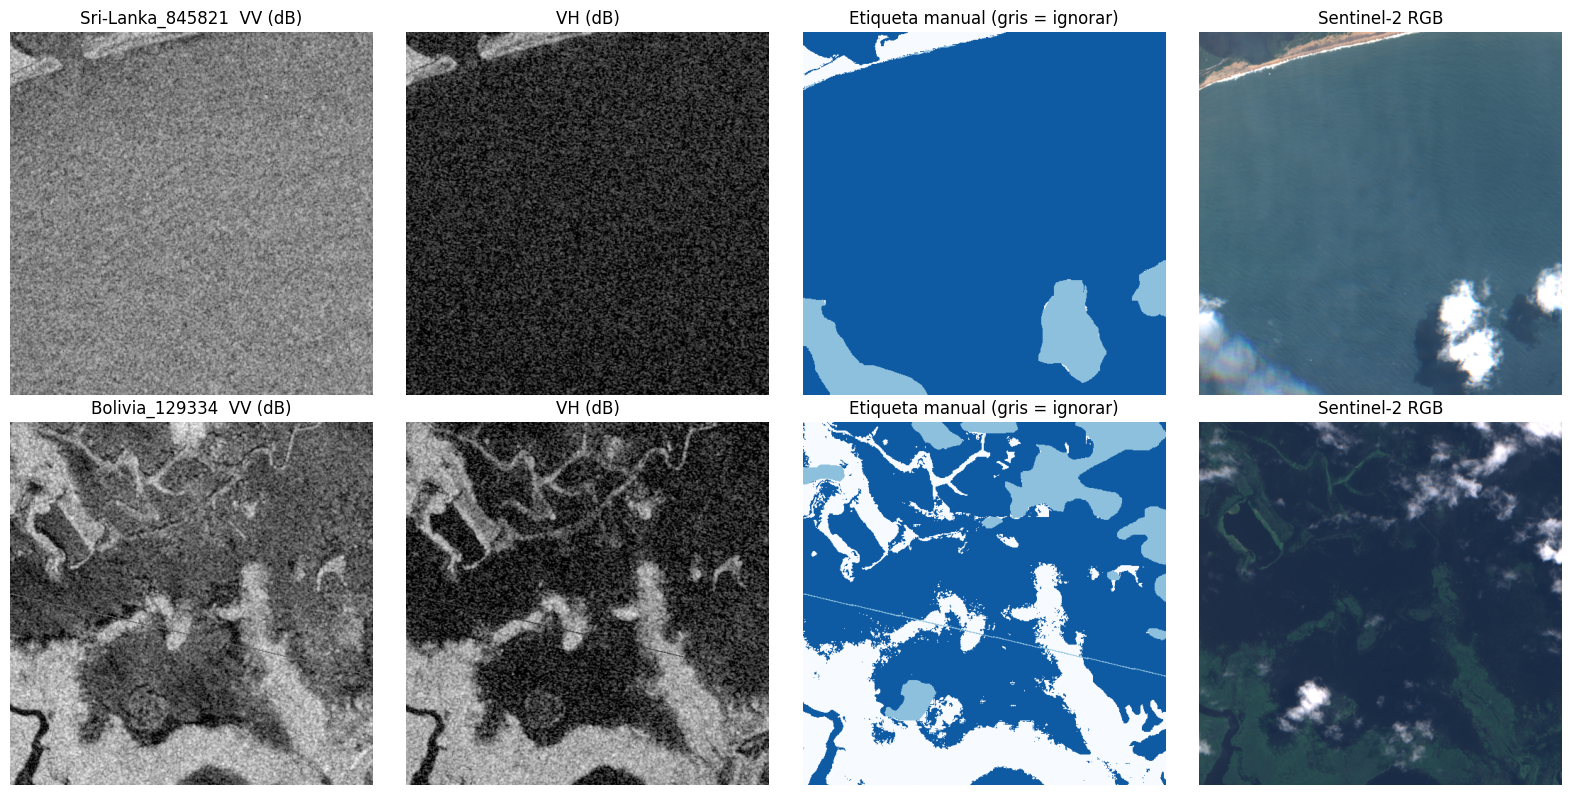

In [ ]:
def iou_np(a, b, valid):
    a, b = a & valid, b & valid
    u = (a | b).sum(); return (a & b).sum() / u if u else np.nan

rows = []
for name, ds in [('train', ds_train), ('valid', ds_valid), ('test', ds_test), ('bolivia', ds_bol)]:
    for i, it in enumerate(ds.items):
        if it['otsu'] is None: continue
        with rasterio.open(it['otsu']) as src: o = fit512(src.read(1), -1)
        y = ds.cache[i][1]; v = y != 255
        rows.append(dict(split=name, event=it['event'], iou_otsu_vs_gold=iou_np(o == 1, y == 1, v),
                         water_gold=(y == 1).sum() / max(v.sum(), 1), water_otsu=((o == 1) & v).sum() / max(v.sum(), 1)))
dfq = pd.DataFrame(rows)
if len(dfq):
    print('IoU(agua) entre etiqueta Otsu-S1 y etiqueta manual (mismos chips):')
    display(dfq.groupby('split')[['iou_otsu_vs_gold', 'water_gold', 'water_otsu']].mean().round(3))
    display(dfq.groupby('event')['iou_otsu_vs_gold'].mean().round(3).to_frame().T)

fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for r, ds in enumerate([ds_train, ds_bol]):
    k = int(np.argmax([(c[1] == 1).sum() for c in ds.cache]))
    s1, y, s2 = ds.cache[k]
    ax[r, 0].imshow(s1[0].astype(float), cmap='gray', vmin=-25, vmax=0); ax[r, 0].set_title(f'{ds.items[k]["id"]}  VV (dB)')
    ax[r, 1].imshow(s1[1].astype(float), cmap='gray', vmin=-30, vmax=-5); ax[r, 1].set_title('VH (dB)')
    ax[r, 2].imshow(np.where(y == 255, 0.5, y), cmap='Blues', vmin=0, vmax=1.2); ax[r, 2].set_title('Etiqueta manual (gris = ignorar)')
    if s2 is not None: ax[r, 3].imshow(np.clip(s2[[2, 1, 0]].astype(float).transpose(1, 2, 0) / 0.3, 0, 1)); ax[r, 3].set_title('Sentinel-2 RGB')
    for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.show()

## §3. U-Net implementada desde cero (entregable 1)
Sin librerías de segmentación. Opciones configurables, usadas en la ablación:
* `depth` (nº de niveles de pooling), `base` (canales base), `dropout` en el cuello de botella.
* `use_skip=False` → quita las conexiones de salto (para medir su aporte).
* `attention=True` → **Attention U-Net**: cada salto pasa por una compuerta de atención (Oktay et al., 2018) controlada por la señal del decodificador.

Entrada: `in_ch=2` (VV, VH); en el bono `in_ch=8`. Salida: 1 logit por píxel (agua).

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, cin, cout, p=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Dropout2d(p) if p > 0 else nn.Identity())
    def forward(self, x): return self.net(x)

class AttentionGate(nn.Module):
    # g: señal del decodificador (ya upsampleada), x: skip del codificador (misma resolución)
    def __init__(self, cg, cx, ci):
        super().__init__()
        self.wg = nn.Sequential(nn.Conv2d(cg, ci, 1), nn.BatchNorm2d(ci))
        self.wx = nn.Sequential(nn.Conv2d(cx, ci, 1), nn.BatchNorm2d(ci))
        self.psi = nn.Sequential(nn.Conv2d(ci, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
    def forward(self, g, x): return x * self.psi(F.relu(self.wg(g) + self.wx(x)))

class UNet(nn.Module):
    def __init__(self, in_ch=2, base=32, depth=4, attention=False, use_skip=True, dropout=0.1):
        super().__init__()
        self.depth, self.attention, self.use_skip = depth, attention, use_skip
        ch = [base * 2 ** i for i in range(depth + 1)]
        self.enc = nn.ModuleList([DoubleConv(in_ch if i == 0 else ch[i - 1], ch[i]) for i in range(depth)])
        self.pool = nn.MaxPool2d(2)
        self.bott = DoubleConv(ch[depth - 1], ch[depth], p=dropout)
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in range(depth)])
        self.att = nn.ModuleList([AttentionGate(ch[i], ch[i], max(ch[i] // 2, 4)) if (attention and use_skip) else nn.Identity() for i in range(depth)])
        self.dec = nn.ModuleList([DoubleConv(ch[i] * 2 if use_skip else ch[i], ch[i]) for i in range(depth)])
        self.out = nn.Conv2d(ch[0], 1, 1)
    def forward(self, x):
        skips, h = [], x
        for e in self.enc:
            h = e(h); skips.append(h); h = self.pool(h)
        h = self.bott(h)
        for i in reversed(range(self.depth)):
            h = self.up[i](h)
            if self.use_skip:
                sk = self.att[i](h, skips[i]) if self.attention else skips[i]
                h = torch.cat([sk, h], 1)
            h = self.dec[i](h)
        return self.out(h).squeeze(1)

def build_model(in_ch=2, **arch):
    kw = dict(base=CFG['BASE']); kw.update(arch)
    return UNet(in_ch=in_ch, **kw)

m = build_model(); n = sum(p.numel() for p in m.parameters())
print(f'U-Net base: {n/1e6:.2f} M parámetros | salida', tuple(m(torch.randn(2, 2, 256, 256)).shape))
del m

U-Net base: 7.76 M parámetros | salida (2, 256, 256)


## §4. Pérdidas, entrenamiento y métricas
* **BCE** enmascarada (ignora `255`), **Dice** suave sobre la clase agua, y **combinada** (0.5·BCE + 0.5·Dice).
* Entrenamiento por **número fijo de pasos** (comparación justa entre configuraciones), AdamW + OneCycle, AMP en GPU.
* Se guarda el checkpoint con mejor **IoU de validación** (conjunto `flood_valid_data`).
* Métricas sobre la clase *agua*: IoU, F1, precisión, recall, omisión (=1−recall), comisión (=1−precisión). Se reportan **agrupadas por píxeles** y **promedio por chip** (como los autores).

In [ ]:
def masked_bce(logits, y):
    m = (y != 255).float(); t = (y == 1).float()
    l = F.binary_cross_entropy_with_logits(logits, t, reduction='none')
    return (l * m).sum() / m.sum().clamp(min=1)

def masked_dice(logits, y, eps=1.0):
    m = (y != 255).float(); p = torch.sigmoid(logits) * m; t = (y == 1).float() * m
    return 1 - (2 * (p * t).sum() + eps) / (p.sum() + t.sum() + eps)

LOSSES = {'bce': masked_bce, 'dice': masked_dice,
          'bce_dice': lambda lg, y: 0.5 * masked_bce(lg, y) + 0.5 * masked_dice(lg, y)}

@torch.no_grad()
def predict_probs(model, ds, bs=8):
    model.eval().to(DEVICE)
    probs = np.zeros((len(ds), 512, 512), np.float16); labels = np.zeros((len(ds), 512, 512), np.uint8)
    for s in range(0, len(ds), bs):
        batch = [ds[i] for i in range(s, min(s + bs, len(ds)))]
        x = torch.stack([b[0] for b in batch]).to(DEVICE)
        with torch.autocast(device_type='cuda', enabled=USE_AMP):
            p = torch.sigmoid(model(x).float())
        probs[s:s + len(batch)] = p.cpu().numpy().astype(np.float16)
        labels[s:s + len(batch)] = torch.stack([b[1] for b in batch]).numpy().astype(np.uint8)
    return probs, labels

THR = 0.5   # umbral de decisión; se calibra SOLO en validación tras elegir el modelo final (§5)

def metrics(probs, labels, thr=None):
    thr = THR if thr is None else thr
    pred = probs.astype(np.float32) > thr; valid = labels != 255; t = labels == 1
    tp_c = (pred & t & valid).sum((1, 2)); fp_c = (pred & ~t & valid).sum((1, 2))
    fn_c = (~pred & t & valid).sum((1, 2)); tn_c = (~pred & ~t & valid).sum((1, 2))
    tp, fp, fn, tn = tp_c.sum(), fp_c.sum(), fn_c.sum(), tn_c.sum()
    d = lambda a, b: float(a / b) if b else float('nan')
    prec, rec = d(tp, tp + fp), d(tp, tp + fn)
    with np.errstate(invalid='ignore', divide='ignore'):
        chip_iou = np.where((tp_c + fp_c + fn_c) > 0, tp_c / np.maximum(tp_c + fp_c + fn_c, 1), np.nan)
    return dict(iou=d(tp, tp + fp + fn), f1=d(2 * tp, 2 * tp + fp + fn), precision=prec, recall=rec,
                omission=1 - rec, commission=1 - prec, miou_chip=float(np.nanmean(chip_iou)),
                tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn), chip_iou=chip_iou)

def evaluate_ds(model, ds): return metrics(*predict_probs(model, ds))

def train_model(model, train_ds, iters, loss_name, lr, val_ds, weights=None, tag=''):
    model.to(DEVICE); crit = LOSSES[loss_name]
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG['WD'])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=iters, pct_start=0.15)
    n = iters * CFG['BATCH']
    sampler = WeightedRandomSampler(weights, n, replacement=True) if weights is not None else torch.utils.data.RandomSampler(train_ds, replacement=True, num_samples=n)
    loader = DataLoader(train_ds, batch_size=CFG['BATCH'], sampler=sampler, num_workers=0, drop_last=True)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    best, best_state, hist, run = -1, None, [], 0.0
    pbar = tqdm(enumerate(loader, 1), total=iters, desc=tag, leave=False)
    for it, (x, y) in pbar:
        model.train(); x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type='cuda', enabled=USE_AMP):
            logits = model(x)
        loss = crit(logits.float(), y)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        run = 0.98 * run + 0.02 * loss.item() if it > 1 else loss.item()
        if it % CFG['EVAL_EVERY'] == 0 or it == iters:
            v = evaluate_ds(model, val_ds)['iou']; hist.append((it, run, v))
            if v > best: best, best_state = v, {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
            pbar.set_postfix(loss=f'{run:.3f}', val_iou=f'{v:.3f}', best=f'{best:.3f}')
    model.load_state_dict(best_state)
    return model, hist, best

## §5. Estudio de ablación (entregable 2)
Cada configuración se entrena con el **mismo presupuesto de pasos** y se evalúa en validación, test (eventos vistos) y Bolivia. **La elección del mejor modelo se hace solo con validación.**

| Grupo | Pregunta | Configuraciones |
|---|---|---|
| **A** (datos) | ¿ayudan los chips de etiqueta débil? | A1 solo dorada · A2 dorada+débil mezcladas (50/50 por batch) · A3 pre-entrenar con débil → afinar con dorada |
| **B** (pérdida) | BCE vs Dice vs combinada | B1 BCE · B2 Dice · (A1 = combinada) |
| **C** (arquitectura) | saltos / profundidad | C1 profundidad 3 · C2 Attention U-Net · C3 sin saltos · (A1 = profundidad 4 con saltos simples) |

In [ ]:
EXPS = [
    dict(name='A1_dorada | BCE+Dice | U-Net d4', data='gold', loss='bce_dice', arch={}),
    dict(name='A2_dorada+debil (mezcla)',        data='mix',  loss='bce_dice', arch={}),
    dict(name='A3_debil->afinar dorada',         data='pre_ft', loss='bce_dice', arch={}),
    dict(name='B1_dorada | BCE',                 data='gold', loss='bce',      arch={}),
    dict(name='B2_dorada | Dice',                data='gold', loss='dice',     arch={}),
    dict(name='C1_dorada | profundidad 3',       data='gold', loss='bce_dice', arch=dict(depth=3)),
    dict(name='C2_dorada | Attention U-Net',     data='gold', loss='bce_dice', arch=dict(attention=True)),
    dict(name='C3_dorada | sin saltos',          data='gold', loss='bce_dice', arch=dict(use_skip=False)),
]
if ds_weak is None: EXPS = [e for e in EXPS if e['data'] in ('gold',)]

def run_exp(exp, seed):
    set_seed(seed); model = build_model(**exp['arch']); tag = f"{exp['name'][:2]}-s{seed}"
    if exp['data'] == 'gold':
        model, hist, best = train_model(model, ds_train, CFG['ITERS'], exp['loss'], CFG['LR'], ds_valid, tag=tag)
    elif exp['data'] == 'mix':
        w = np.r_[np.full(len(ds_train), (1 - CFG['WEAK_FRAC']) / len(ds_train)), np.full(len(ds_weak), CFG['WEAK_FRAC'] / len(ds_weak))]
        model, hist, best = train_model(model, ConcatDataset([ds_train, ds_weak]), CFG['ITERS'], exp['loss'], CFG['LR'], ds_valid, weights=w, tag=tag)
    elif exp['data'] == 'pre_ft':
        model, h1, _ = train_model(model, ds_weak, CFG['PRE_ITERS'], exp['loss'], CFG['LR'], ds_valid, tag=tag + '-pre')
        model, h2, best = train_model(model, ds_train, CFG['FT_ITERS'], exp['loss'], CFG['FT_LR'], ds_valid, tag=tag + '-ft'); hist = h1 + h2
    row = dict(exp=exp['name'], seed=seed)
    for nm, ds in [('valid', ds_valid), ('test', ds_test), ('bolivia', ds_bol)]:
        r = evaluate_ds(model, ds)
        for k in ['iou', 'f1', 'precision', 'recall', 'miou_chip']: row[f'{nm}_{k}'] = r[k]
    return row, {k: v.cpu().clone() for k, v in model.state_dict().items()}, hist

ROWS, MODELS, HISTS = [], {}, {}
t0 = time.time()
for exp in EXPS:
    for seed in CFG['SEEDS']:
        row, sd, hist = run_exp(exp, seed); ROWS.append(row); HISTS[(exp['name'], seed)] = hist
        if seed == CFG['SEEDS'][0]: MODELS[exp['name']] = (exp['arch'], sd)
        print(f"{exp['name']:<42} s{seed} | val IoU {row['valid_iou']:.3f} | test IoU {row['test_iou']:.3f} | Bolivia IoU {row['bolivia_iou']:.3f} | {time.time()-t0:.0f}s")
res = pd.DataFrame(ROWS); res.to_csv(f'{OUT_DIR}/ablacion_resultados.csv', index=False)

A1-s0:   0%|          | 0/1500 [00:00<?, ?it/s]

A1_dorada | BCE+Dice | U-Net d4            s0 | val IoU 0.630 | test IoU 0.676 | Bolivia IoU 0.639 | 215s


A2-s0:   0%|          | 0/1500 [00:00<?, ?it/s]

A2_dorada+debil (mezcla)                   s0 | val IoU 0.585 | test IoU 0.628 | Bolivia IoU 0.696 | 422s


A3-s0-pre:   0%|          | 0/2500 [00:00<?, ?it/s]

...

C1_dorada | profundidad 3                  s0 | val IoU 0.623 | test IoU 0.668 | Bolivia IoU 0.584 | 1465s


C2-s0:   0%|          | 0/1500 [00:00<?, ?it/s]

C2_dorada | Attention U-Net                s0 | val IoU 0.631 | test IoU 0.670 | Bolivia IoU 0.528 | 1709s


C3-s0:   0%|          | 0/1500 [00:00<?, ?it/s]

C3_dorada | sin saltos                     s0 | val IoU 0.595 | test IoU 0.622 | Bolivia IoU 0.640 | 1895s


,valid_iou,test_iou,test_f1,test_precision,test_recall,bolivia_iou
exp,,,,,,
A1_dorada | BCE+Dice | U-Net d4,0.630,0.676,0.807,0.822,0.791,0.639
A2_dorada+debil (mezcla),0.585,0.628,0.772,0.792,0.753,0.696
A3_debil->afinar dorada,0.629,0.657,0.793,0.824,0.765,0.594
B1_dorada | BCE,0.611,0.649,0.787,0.851,0.733,0.547
B2_dorada | Dice,0.630,0.675,0.806,0.819,0.793,0.611
C1_dorada | profundidad 3,0.623,0.668,0.801,0.817,0.785,0.584
C2_dorada | Attention U-Net,0.631,0.670,0.803,0.839,0.769,0.528
C3_dorada | sin saltos,0.595,0.622,0.767,0.773,0.761,0.640


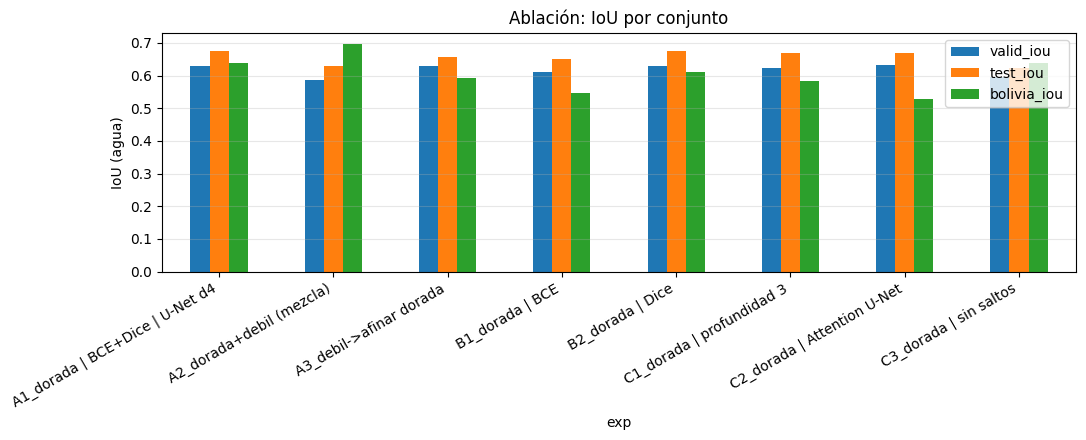

Modelo final (mejor IoU de validación): C2_dorada | Attention U-Net
Umbral calibrado en validación: 0.25 (IoU valid 0.6409 vs 0.6314 con 0.5). Se usa en §6-§9.


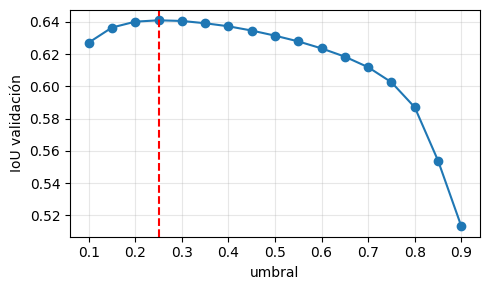

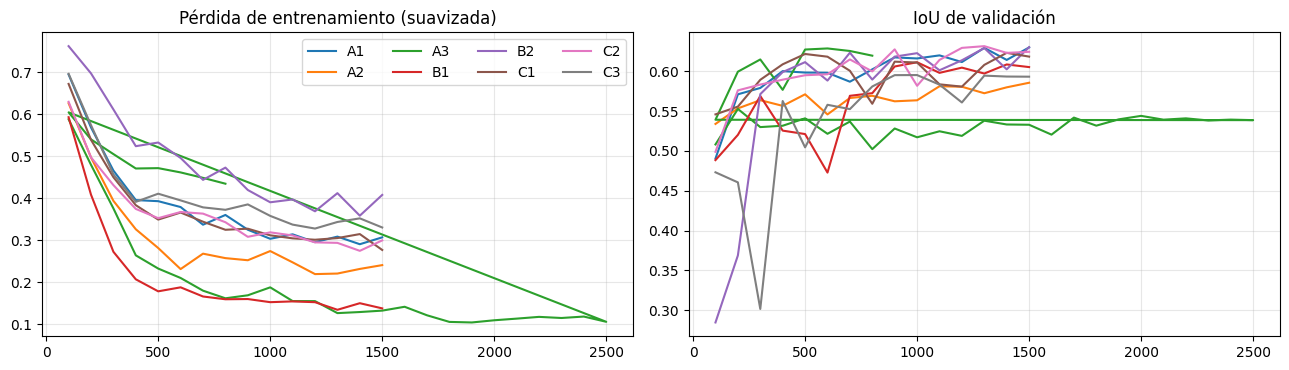

In [ ]:
cols = ['valid_iou', 'test_iou', 'test_f1', 'test_precision', 'test_recall', 'bolivia_iou']
summ = res.groupby('exp', sort=False)[cols].agg(['mean', 'std']) if len(CFG['SEEDS']) > 1 else res.set_index('exp')[cols]
display(summ.round(3))

fig, ax = plt.subplots(figsize=(11, 4.5)); g = res.groupby('exp', sort=False)[['valid_iou', 'test_iou', 'bolivia_iou']].mean()
g.plot.bar(ax=ax, rot=30); ax.set_ylabel('IoU (agua)'); ax.set_title('Ablación: IoU por conjunto'); ax.grid(axis='y', alpha=.3)
plt.xticks(ha='right'); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/ablacion_barras.png', dpi=150); plt.show()

# selección del modelo final: SOLO por IoU de validación
FINAL = res.groupby('exp')['valid_iou'].mean().idxmax()
print('Modelo final (mejor IoU de validación):', FINAL)
FINAL_ARCH, FINAL_SD = MODELS[FINAL]
final_model = build_model(**FINAL_ARCH); final_model.load_state_dict(FINAL_SD)
torch.save(dict(arch=FINAL_ARCH, state=FINAL_SD, cfg=CFG), f'{OUT_DIR}/modelo_final.pt')

# calibración del umbral de decisión: SOLO con validación (nunca con test ni Bolivia)
pv, lv = predict_probs(final_model, ds_valid)
grid = np.round(np.arange(0.10, 0.91, 0.05), 2); ious = [metrics(pv, lv, thr=t)['iou'] for t in grid]
THR_05_VALID_IOU = metrics(pv, lv, thr=0.5)['iou']
THR = float(grid[int(np.argmax(ious))])
print(f'Umbral calibrado en validación: {THR:.2f} (IoU valid {max(ious):.4f} vs {THR_05_VALID_IOU:.4f} con 0.5). Se usa en §6-§9.')
plt.figure(figsize=(5, 3)); plt.plot(grid, ious, marker='o'); plt.axvline(THR, ls='--', c='r'); plt.xlabel('umbral'); plt.ylabel('IoU validación'); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/umbral_validacion.png', dpi=150); plt.show()

# curvas de entrenamiento de las corridas (semilla 0)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for (nm, sd), h in HISTS.items():
    if sd != CFG['SEEDS'][0]: continue
    h = np.array(h); ax[0].plot(h[:, 0], h[:, 1], label=nm[:2]); ax[1].plot(h[:, 0], h[:, 2], label=nm[:2])
ax[0].set_title('Pérdida de entrenamiento (suavizada)'); ax[1].set_title('IoU de validación'); ax[0].legend(ncol=4); ax[1].grid(alpha=.3); ax[0].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Cómo redactar la conclusión de la ablación (completar con TUS números):**
* (a) Compara A1, A2, A3 en *validación y test*. Pregunta clave: ¿la señal débil (ruidosa, ver IoU Otsu-vs-manual en §2) añade información útil o solo ruido? Fíjate también en **Bolivia** (¿la supervisión débil ayuda a generalizar?, recuerda que no se usó para elegir).
* (b) BCE sufre con desbalance (el agua es minoría) → suele omitir agua; Dice optimiza directamente el solapamiento pero puede ser inestable; la combinada suele ser un buen compromiso. Contrasta con precisión/recall en test.
* (c) Efecto de profundidad, de las compuertas de atención y de quitar los saltos (los saltos aportan detalle espacial fino → bordes del agua).
* Con 1 sola semilla las diferencias pequeñas (< ~0.01 IoU) **no son concluyentes**: indícalo o usa `SEEDS=[0,1,2]`.

## §6. Evaluación en distribución (entregable 3)
Test oficial (`flood_test_data.csv`): chips dorados de **eventos vistos durante el entrenamiento** (otros chips de los mismos eventos).

Umbral de decisión usado: 0.25 (calibrado en validación) | IoU test con umbral 0.5: 0.6702
Modelo: C2_dorada | Attention U-Net
iou           0.6704
f1            0.8027
precision     0.7954
recall        0.8100
omission      0.1900
commission    0.2046
miou_chip     0.4099


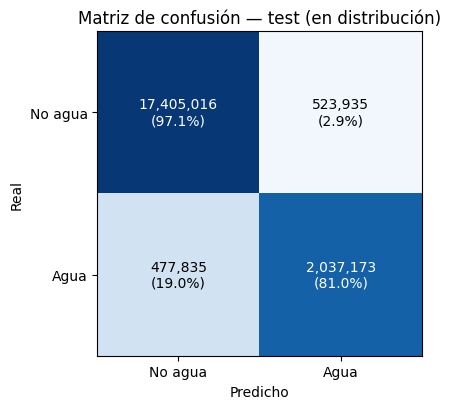


Lectura automática: de cada 100 píxeles de agua real, el modelo detecta 81.0 y pierde 19.0 (omisión). De cada 100 píxeles que marca como agua, 20.5 son falsos (comisión). El agua es 12.3% de los píxeles válidos: por eso la exactitud global engaña y se usa IoU/F1.


event,Ghana,India,Mekong,Nigeria,Pakistan,Paraguay,Somalia,Spain,Sri-Lanka,USA
mean,0.322,0.449,0.444,0.459,0.179,0.485,0.297,0.489,0.422,0.429
count,8.000,14.000,6.000,4.000,6.000,13.000,6.000,6.000,9.000,14.000


In [ ]:
probs_test, labels_test = predict_probs(final_model, ds_test)
mt = metrics(probs_test, labels_test)
print(f'Umbral de decisión usado: {THR:.2f} (calibrado en validación) | IoU test con umbral 0.5: {metrics(probs_test, labels_test, thr=0.5)["iou"]:.4f}')
print(f"Modelo: {FINAL}")
print(pd.Series({k: round(mt[k], 4) for k in ['iou', 'f1', 'precision', 'recall', 'omission', 'commission', 'miou_chip']}).to_string())

def plot_cm(m, title, ax):
    cm = np.array([[m['tn'], m['fp']], [m['fn'], m['tp']]], float); cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2): ax.text(j, i, f'{cm[i,j]:,.0f}\n({cmn[i,j]:.1%})', ha='center', va='center', color='white' if cmn[i, j] > .5 else 'black')
    ax.set_xticks([0, 1], ['No agua', 'Agua']); ax.set_yticks([0, 1], ['No agua', 'Agua']); ax.set_xlabel('Predicho'); ax.set_ylabel('Real'); ax.set_title(title)
fig, ax = plt.subplots(figsize=(4.8, 4.2)); plot_cm(mt, 'Matriz de confusión — test (en distribución)', ax)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/cm_test.png', dpi=150); plt.show()

print(f"\nLectura automática: de cada 100 píxeles de agua real, el modelo detecta {mt['recall']*100:.1f} y pierde {mt['omission']*100:.1f} (omisión). "
      f"De cada 100 píxeles que marca como agua, {mt['commission']*100:.1f} son falsos (comisión). "
      f"El agua es {(mt['tp']+mt['fn'])/(mt['tp']+mt['fn']+mt['fp']+mt['tn']):.1%} de los píxeles válidos: por eso la exactitud global engaña y se usa IoU/F1.")

# IoU por evento (test)
ev = pd.DataFrame(dict(event=[it['event'] for it in ds_test.items], chip_iou=mt['chip_iou']))
display(ev.groupby('event')['chip_iou'].agg(['mean', 'count']).round(3).T)

**Comentario de la matriz (plantilla):** (1) la diagonal domina porque el agua es minoritaria; (2) compara FN (agua perdida) vs FP (falsa alarma): ¿cuál error es mayor? Eso indica si el modelo es conservador u optimista; (3) en una respuesta de emergencia suele ser más costoso omitir agua (FN) que sobre-estimarla → discute si convendría bajar el umbral de decisión; (4) menciona los eventos con peor IoU de la tabla y la relación con la cobertura del suelo.

## §7. Generalización geográfica: Bolivia (entregable 4)
Los conjuntos train/valid/test oficiales **excluyen Bolivia**; evaluamos el mismo modelo final solo sobre los 15 chips dorados de Bolivia y medimos la brecha frente al punto 3. (Los chips débiles de Bolivia también se excluyeron del entrenamiento.)

,Test (eventos vistos),Bolivia (región no vista),Brecha (test - Bolivia)
iou,0.6704,0.5926,0.0778
f1,0.8027,0.7442,0.0585
precision,0.7954,0.8537,-0.0583
recall,0.8100,0.6595,0.1505
miou_chip,0.4099,0.3709,0.0391


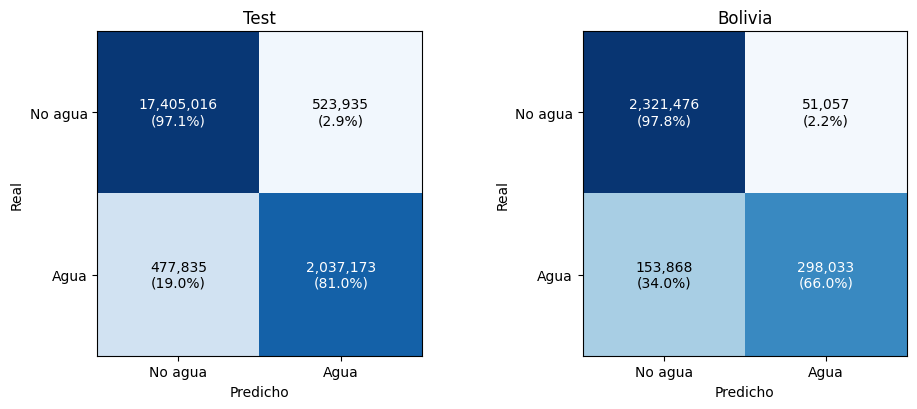

IoU por chip en Bolivia: [0.77 0.83 0.02 0.75 0.   0.16 0.46 0.73 0.06 0.54 0.05 0.23 0.39 0.57
 0.  ]
Omisión: test 19.0% vs Bolivia 34.0% | Comisión: test 20.5% vs Bolivia 14.6%
Nota: Bolivia tiene solo 15 chips -> la brecha tiene alta incertidumbre; reporta el IoU por chip y evita sobre-interpretar.


In [ ]:
probs_bol, labels_bol = predict_probs(final_model, ds_bol)
mb = metrics(probs_bol, labels_bol)
keys = ['iou', 'f1', 'precision', 'recall', 'miou_chip']
gap = pd.DataFrame({'Test (eventos vistos)': [mt[k] for k in keys], 'Bolivia (región no vista)': [mb[k] for k in keys]}, index=keys)
gap['Brecha (test - Bolivia)'] = gap.iloc[:, 0] - gap.iloc[:, 1]
display(gap.round(4)); gap.to_csv(f'{OUT_DIR}/brecha_bolivia.csv')

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2)); plot_cm(mt, 'Test', ax[0]); plot_cm(mb, 'Bolivia', ax[1])
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/cm_test_vs_bolivia.png', dpi=150); plt.show()
print('IoU por chip en Bolivia:', np.round(mb['chip_iou'], 2))
print(f"Omisión: test {mt['omission']:.1%} vs Bolivia {mb['omission']:.1%} | Comisión: test {mt['commission']:.1%} vs Bolivia {mb['commission']:.1%}")
if len(ds_bol) < 20: print('Nota: Bolivia tiene solo', len(ds_bol), 'chips -> la brecha tiene alta incertidumbre; reporta el IoU por chip y evita sobre-interpretar.')

### Pruebas empíricas de las hipótesis sobre la brecha
Se cuantifican posibles causas con datos (no solo se enuncian):
* **H1 – Cambio de distribución de retrodispersión** (covariate shift): ¿Bolivia tiene valores VV/VH de agua/tierra distintos a los de los eventos de entrenamiento? (distancia de Wasserstein + histogramas).
* **H2 – Geometría de adquisición** (órbita/ángulo de incidencia): el dataset no trae el ángulo local, pero sí órbita, nº de órbita relativa y umbral VH de cada evento (metadatos del GeoJSON). Se compara el IoU por tipo de órbita.
* **H3 – Cobertura del suelo / vegetación inundada**: NDVI medio del suelo seco (S2) y tasa de error según nivel de retrodispersión.
* **H4 – Prevalencia de agua y ruido de etiqueta**: fracción de agua por evento.

,water_frac,vh_water,vh_land,vv_water,vv_land,ndvi_land,n_chips,orbita,rel_orbit,VH_thresh
event,,,,,,,,,,
USA,0.046,-24.632,-17.178,-16.898,-10.989,0.521,69,ASC,136,-22.62
Somalia,0.062,-21.526,-18.453,-14.333,-12.095,0.256,26,ASC,116,-21.06
Ghana,0.064,-21.866,-16.003,-14.136,-9.543,0.453,53,ASC,147,-22.81
Pakistan,0.076,-23.284,-17.997,-14.445,-9.929,0.146,28,DESC,5,-19.56
Paraguay,0.079,-24.410,-16.742,-15.846,-9.689,0.476,67,DESC,68,-19.94
Sri-Lanka,0.112,-21.620,-15.364,-13.211,-8.932,0.429,42,DESC,19,-21.69
India,0.128,-20.878,-15.375,-13.450,-8.536,0.506,68,DESC,77,-21.56
Spain,0.141,-25.387,-17.237,-17.853,-10.128,0.252,30,DESC,110,-25.13
Bolivia,0.170,-21.399,-15.062,-14.381,-8.768,0.558,15,DESC,156,-20.44



H1: distancia de Wasserstein (dB) entre Bolivia y cada evento de entrenamiento (mayor = más distinto):


,W_VH_agua,W_VH_tierra
Sri-Lanka,0.64,0.59
Paraguay,1.36,1.91
India,1.68,0.57
Pakistan,1.84,3.31
Nigeria,2.24,1.29
Ghana,2.28,1.04
Somalia,2.44,3.50
USA,2.53,2.33
Mekong,3.80,0.32
Spain,4.73,2.33


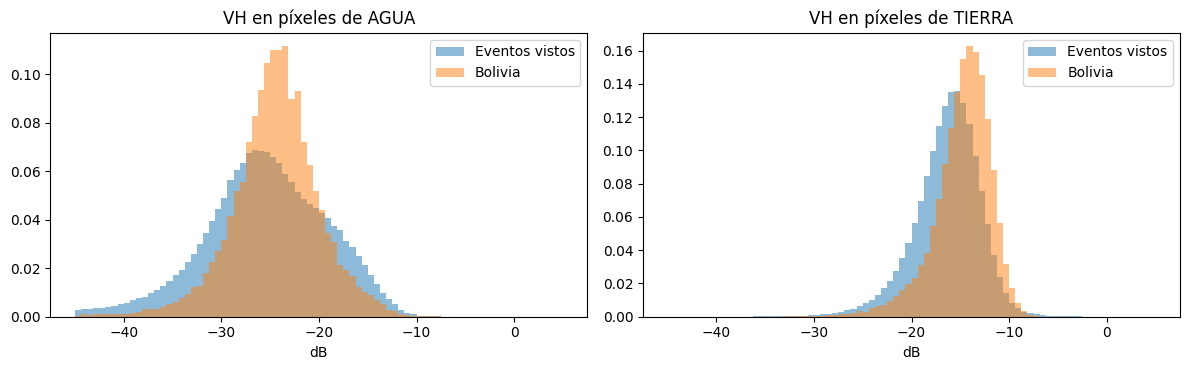


H2: IoU por chip en test según órbita (Bolivia = DESC, rel. orbit 156):


,mean,count
orbita,,
ASC,0.391,38
DESC,0.425,48



H3: tasas de error por rango de VH (dB):


Test                                     Bolivia          \
          pixeles_agua FN_rate pixeles_tierra FP_rate pixeles_agua FN_rate   
bin_VH                                                                       
[-50,-26)      1192249   0.012         235876   0.583       147086   0.152   
[-26,-22)       668715   0.092         770404   0.224       185586   0.293   
[-22,-18)       379704   0.455        3634521   0.043        88714   0.588   
[-18,-14)       222184   0.806        8956894   0.006        25981   0.794   
[-14,1)          52131   0.958        4329911   0.001         4528   0.947   

                                  
          pixeles_tierra FP_rate  
bin_VH                            
[-50,-26)          15865   0.529  
[-26,-22)          54130   0.292  
[-22,-18)         224213   0.086  
[-18,-14)        1042017   0.007  
[-14,1)          1036308   0.000

In [ ]:
META = {  # Sen1Floods11_Metadata.geojson: orbit, rel_orbit_num, VH_thresh (umbral Otsu-VH usado en la etiqueta débil S1)
 'Bolivia': ('DESC',156,-20.44), 'Colombia': ('ASC',106,-21.31), 'Ghana': ('ASC',147,-22.81), 'India': ('DESC',77,-21.56),
 'Cambodia': ('ASC',26,-23.06), 'Nigeria': ('ASC',103,-21.94), 'Pakistan': ('DESC',5,-19.56), 'Paraguay': ('DESC',68,-19.94),
 'Somalia': ('ASC',116,-21.06), 'Spain': ('DESC',110,-25.13), 'Sri-Lanka': ('DESC',19,-21.69), 'USA': ('ASC',136,-22.62),
 'Mekong': ('ASC',26,-23.06)}  # Added Mekong to prevent KeyError

def chip_stats(ds, split):
    rows = []
    for i, it in enumerate(ds.items):
        s1, y, s2 = ds.cache[i]; v = y != 255; w = (y == 1); l = (y == 0)
        r = dict(split=split, event=it['event'], water_frac=w.sum() / max(v.sum(), 1),
                 vh_water=float(s1[1][w].astype(np.float32).mean()) if w.any() else np.nan, vh_land=float(s1[1][l].astype(np.float32).mean()) if l.any() else np.nan,
                 vv_water=float(s1[0][w].astype(np.float32).mean()) if w.any() else np.nan, vv_land=float(s1[0][l].astype(np.float32).mean()) if l.any() else np.nan)
        if s2 is not None and l.any():
            b4, b8 = s2[2].astype(np.float32), s2[3].astype(np.float32); r['ndvi_land'] = float(((b8 - b4) / (b8 + b4 + 1e-6))[l].mean())
        rows.append(r)
    return rows
cs = pd.DataFrame(sum([chip_stats(ds, n) for n, ds in [('train', ds_train), ('valid', ds_valid), ('test', ds_test), ('bolivia', ds_bol)]], []))
evt = cs.groupby('event').mean(numeric_only=True); evt['n_chips'] = cs.groupby('event').size()

# Safely map to handle any missing meta keys gracefully
evt['orbita'] = [META.get(e, ('UNKNOWN', 0, np.nan))[0] for e in evt.index]
evt['rel_orbit'] = [META.get(e, ('UNKNOWN', 0, np.nan))[1] for e in evt.index]
evt['VH_thresh'] = [META.get(e, ('UNKNOWN', 0, np.nan))[2] for e in evt.index]
display(evt.round(3).sort_values('water_frac'))

# H1: distancia de Wasserstein de Bolivia vs cada evento (VH agua / VH tierra)
def pix(ds, kind, n=60000):
    out = []
    for c in ds.cache:
        s1, y, _ = c; m = (y == (1 if kind == 'water' else 0)); out.append(s1[1][m][::37].astype(np.float32))
    a = np.concatenate(out) if out else np.array([0.]); return a[np.random.RandomState(0).permutation(len(a))[:n]]
allds = [('train', ds_train), ('valid', ds_valid), ('test', ds_test)]
by_event = {}
for _, ds in allds:
    for e in set(it['event'] for it in ds.items):
        sub = subset_idx = [i for i, it in enumerate(ds.items) if it['event'] == e]
        by_event.setdefault(e, []).append((ds, sub))
def event_pix(e, kind):
    out = []
    for ds, idx in by_event[e]:
        for i in idx:
            s1, y, _ = ds.cache[i]; m = (y == (1 if kind == 'water' else 0)); out.append(s1[1][m][::37].astype(np.float32))
    return np.concatenate(out)
bol_w, bol_l = pix(ds_bol, 'water'), pix(ds_bol, 'land')
wd = pd.DataFrame({e: dict(W_VH_agua=wasserstein_distance(bol_w, event_pix(e, 'water')), W_VH_tierra=wasserstein_distance(bol_l, event_pix(e, 'land'))) for e in by_event}).T
print('\nH1: distancia de Wasserstein (dB) entre Bolivia y cada evento de entrenamiento (mayor = más distinto):'); display(wd.round(2).sort_values('W_VH_agua'))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
tr_w = np.concatenate([event_pix(e, 'water') for e in by_event]); tr_l = np.concatenate([event_pix(e, 'land') for e in by_event])
for a, (b, t, ttl) in zip(ax, [(bol_w, tr_w, 'VH en píxeles de AGUA'), (bol_l, tr_l, 'VH en píxeles de TIERRA')]):
    a.hist(t, bins=80, range=(-45, 5), density=True, alpha=.5, label='Eventos vistos'); a.hist(b, bins=80, range=(-45, 5), density=True, alpha=.5, label='Bolivia'); a.set_title(ttl); a.set_xlabel('dB'); a.legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/h1_histogramas.png', dpi=150); plt.show()

# H2: IoU por tipo de órbita en test
ev2 = pd.DataFrame(dict(event=[it['event'] for it in ds_test.items], iou=mt['chip_iou'])); ev2['orbita'] = ev2.event.map(lambda e: META.get(e, ('UNKNOWN',))[0])
print('\nH2: IoU por chip en test según órbita (Bolivia = DESC, rel. orbit 156):'); display(ev2.groupby('orbita')['iou'].agg(['mean', 'count']).round(3))

# H3: tasas de error según nivel de VH (test vs Bolivia)
edges = [-50, -26, -22, -18, -14, 1]
def rates_by_vh(ds, probs, labels):
    vh = np.stack([c[0][1] for c in ds.cache]).astype(np.float32); pred = probs.astype(np.float32) > THR; rows = []
    for a, b in zip(edges[:-1], edges[1:]):
        m = (vh >= a) & (vh < b) & (labels != 255); w = m & (labels == 1); l = m & (labels == 0)
        rows.append(dict(bin_VH=f'[{a},{b})', pixeles_agua=int(w.sum()), FN_rate=float((~pred & w).sum() / max(w.sum(), 1)), pixeles_tierra=int(l.sum()), FP_rate=float((pred & l).sum() / max(l.sum(), 1))))
    return pd.DataFrame(rows).set_index('bin_VH')
print('\nH3: tasas de error por rango de VH (dB):')
display(pd.concat({'Test': rates_by_vh(ds_test, probs_test, labels_test), 'Bolivia': rates_by_vh(ds_bol, probs_bol, labels_bol)}, axis=1).round(3))

**Hipótesis candidatas para redactar (confirma/refuta cada una con las tablas de arriba, no las copies sin mirar los números):**
1. **Cobertura/vegetación inundada**: Bolivia (Beni/Llanos de Moxos) es sabana y bosque amazónico inundado. El agua bajo vegetación produce *doble rebote* → retrodispersión alta → el modelo la clasifica como tierra (FN). Evidencia: H3 (FN alto en bins de VH alto) y NDVI del suelo (§H3).
2. **Cambio de distribución radiométrica / geometría de adquisición**: órbita descendente y ángulo de incidencia distintos desplazan la retrodispersión del agua y la tierra (H1, H2). El modelo aprendió umbrales ligados a los eventos vistos; el umbral Otsu-VH de Bolivia (−20.4 dB) difiere de otros eventos (p. ej. España −25.1 dB).
3. **Ruido/definición de etiqueta y prevalencia de agua** (H4): si Bolivia tiene fracción de agua muy distinta, o etiquetas de agua con vegetación, la métrica cambia por la propia etiqueta, no solo por el modelo.
4. **Tamaño muestral**: solo 15 chips → intervalos de confianza amplios.

## §8. Análisis cualitativo de fallos característicos del SAR (entregable 5)
Se **clasifican automáticamente** los píxeles erróneos de test+Bolivia según reglas físicas sobre la retrodispersión VH (en dB) y se muestran **ejemplos visuales** (recorte de 128×128 donde más se concentra cada tipo), junto a Sentinel-2 RGB como verdad de contexto.

| Tipo | Regla (heurística, ajustable en `ERR_TH`) | Interpretación física |
|---|---|---|
| **FN: agua con retrodispersión alta** | etiqueta=agua, pred=tierra, VH > −18 dB | vegetación inundada / **doble rebote** (urbano o forestal), agua rugosa por viento |
| **FP: muy oscuro** | etiqueta=tierra, pred=agua, VH < −24 dB | **sombra de radar** (relieve), superficies lisas (asfalto, arena seca, suelo compactado) |
| **FP: moderado** | etiqueta=tierra, pred=agua, −24 ≤ VH | **suelo húmedo/saturado**, humedales, zonas de transición |
| **Borde** | error a ≤ 2 px del contorno del agua | píxeles mixtos, resolución, ruido *speckle* |

Adicional (si hay S2): proxy urbano (NDBI>0 y NDVI<0.2) para estimar cuánto FN ocurre sobre superficies construidas/desnudas.

In [ ]:
ERR_TH = dict(fn_bright_vh=-18.0, fp_dark_vh=-24.0, boundary_px=2)
CATS = ['Borde (píxeles mixtos)', 'FN: agua con retrodispersión ALTA (veg. inundada/doble rebote)', 'FN: agua con retrodispersión baja (otros)',
        'FP: muy oscuro (sombra de radar / superficie lisa)', 'FP: moderado (suelo húmedo / transición)']

def categorize(s1, y, pred):
    vh = s1[1].astype(np.float32); valid = y != 255; t = y == 1
    fp, fn = pred & ~t & valid, ~pred & t & valid
    b = ERR_TH['boundary_px']; edge = ndimage.binary_dilation(t, iterations=b) & ~ndimage.binary_erosion(t, iterations=b, border_value=1)
    err = fp | fn; c0 = err & edge; r = err & ~edge
    bright = vh > ERR_TH['fn_bright_vh']; dark = vh < ERR_TH['fp_dark_vh']
    return [c0, r & fn & bright, r & fn & ~bright, r & fp & dark, r & fp & ~dark], fp, fn

EVAL = [('test', ds_test, probs_test), ('bolivia', ds_bol, probs_bol)]
cnt, urban_fn = [], []
for sp, ds, pr in EVAL:
    for i in range(len(ds)):
        s1, y, s2 = ds.cache[i]; pred = pr[i].astype(np.float32) > THR
        cats, fp, fn = categorize(s1, y, pred)
        cnt.append(dict(split=sp, idx=i, id=ds.items[i]['id'], **{c: int(m.sum()) for c, m in zip(CATS, cats)}))
        if s2 is not None:
            b4, b8, b11 = [s2[k].astype(np.float32) for k in (2, 3, 4)]
            urban = ((b11 - b8) / (b11 + b8 + 1e-6) > 0) & ((b8 - b4) / (b8 + b4 + 1e-6) < 0.2)
            urban_fn.append(dict(split=sp, fn_total=int(fn.sum()), fn_urbano=int((fn & urban).sum()), agua_urbano=int(((y == 1) & urban).sum())))
cnt = pd.DataFrame(cnt)
tab = cnt.groupby('split')[CATS].sum(); tab['TOTAL_errores'] = tab.sum(1)
print('Píxeles erróneos por tipo:'); display(tab)
display((tab[CATS].div(tab['TOTAL_errores'], axis=0) * 100).round(1).add_suffix(' (%)').T)
if urban_fn:
    uf = pd.DataFrame(urban_fn).groupby('split').sum(); uf['%FN_sobre_proxy_urbano'] = (100 * uf.fn_urbano / uf.fn_total.clip(lower=1)).round(1); print('\nProxy urbano (S2):'); display(uf)

Píxeles erróneos por tipo:


,Borde (píxeles mixtos),FN: agua con retrodispersión ALTA (veg. inundada/doble rebote),FN: agua con retrodispersión baja (otros),FP: muy oscuro (sombra de radar / superficie lisa),FP: moderado (suelo húmedo / transición),TOTAL_errores
split,,,,,,
bolivia,72555,9107,97595,8551,17117,204925
test,422537,101625,131723,168877,177008,1001770


split,bolivia,test
Borde (píxeles mixtos) (%),35.4,42.2
FN: agua con retrodispersión ALTA (veg. inundada/doble rebote) (%),4.4,10.1
FN: agua con retrodispersión baja (otros) (%),47.6,13.1
FP: muy oscuro (sombra de radar / superficie lisa) (%),4.2,16.9
FP: moderado (suelo húmedo / transición) (%),8.4,17.7



Proxy urbano (S2):


,fn_total,fn_urbano,agua_urbano,%FN_sobre_proxy_urbano
split,,,,
bolivia,153868,4215,13533,2.7
test,477835,14550,47077,3.0


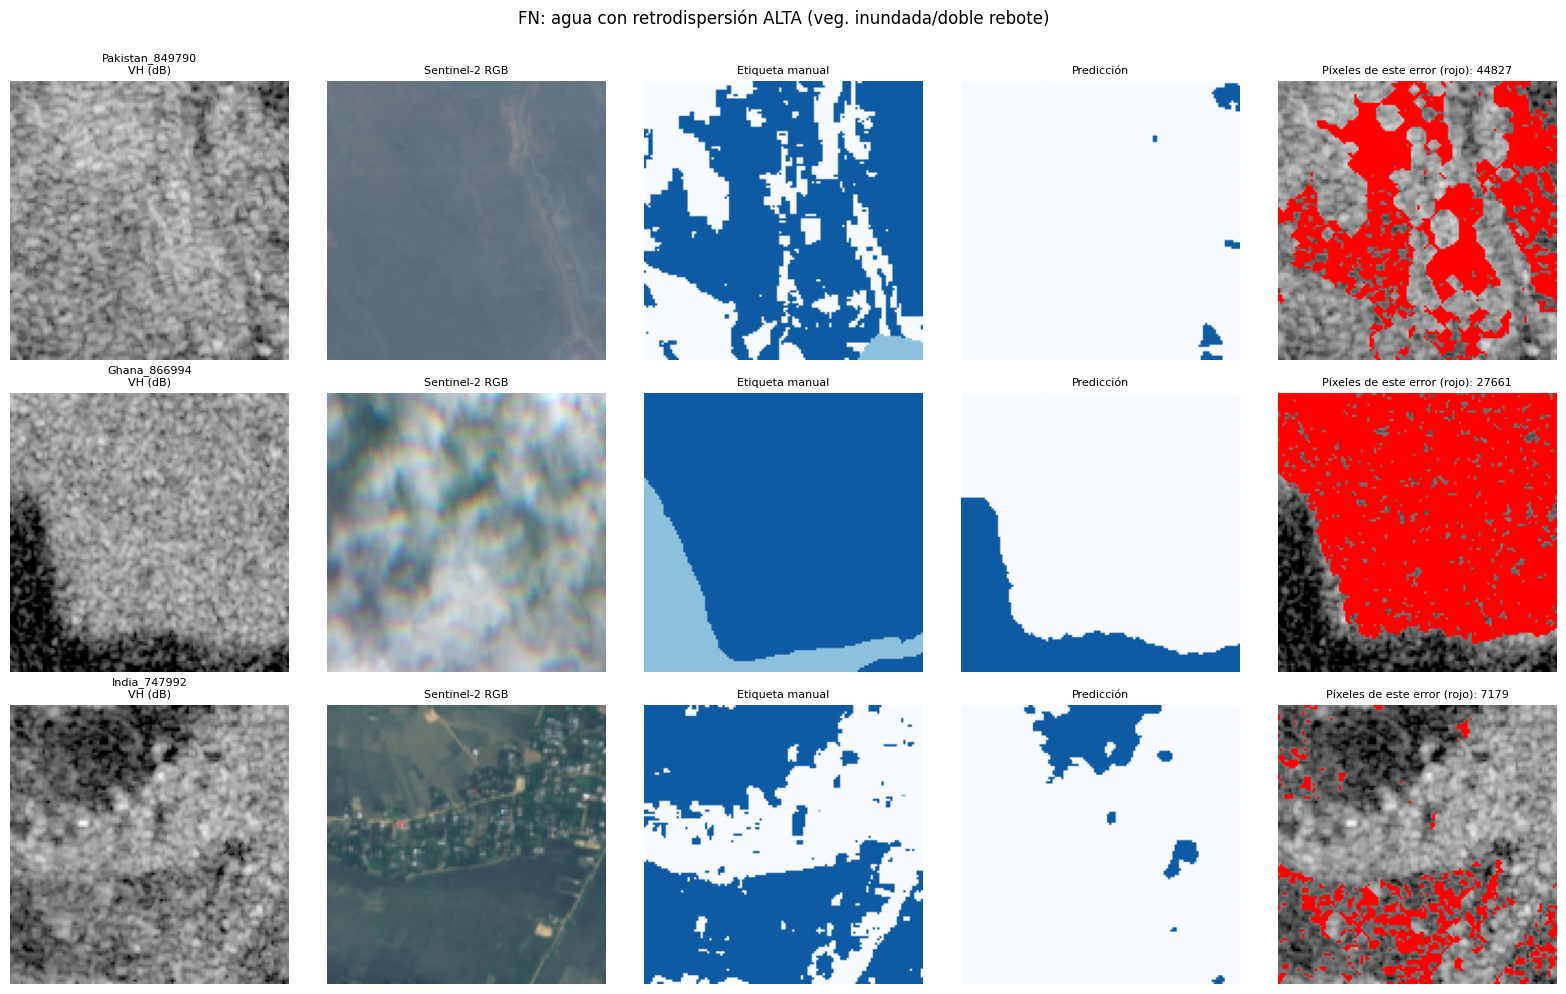

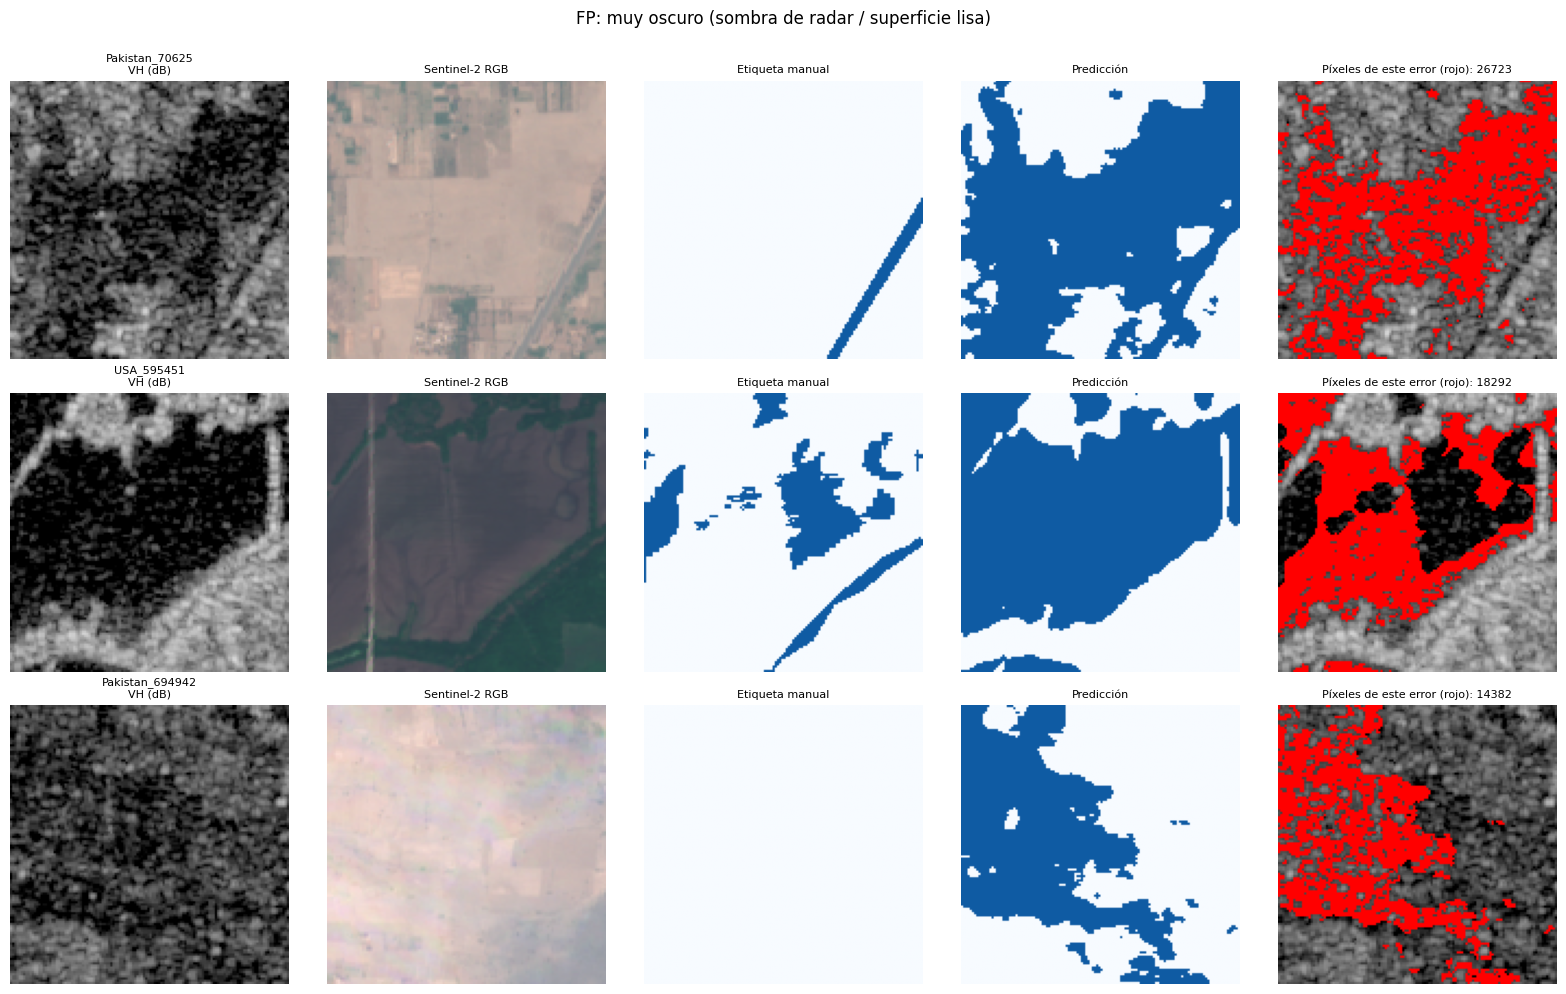

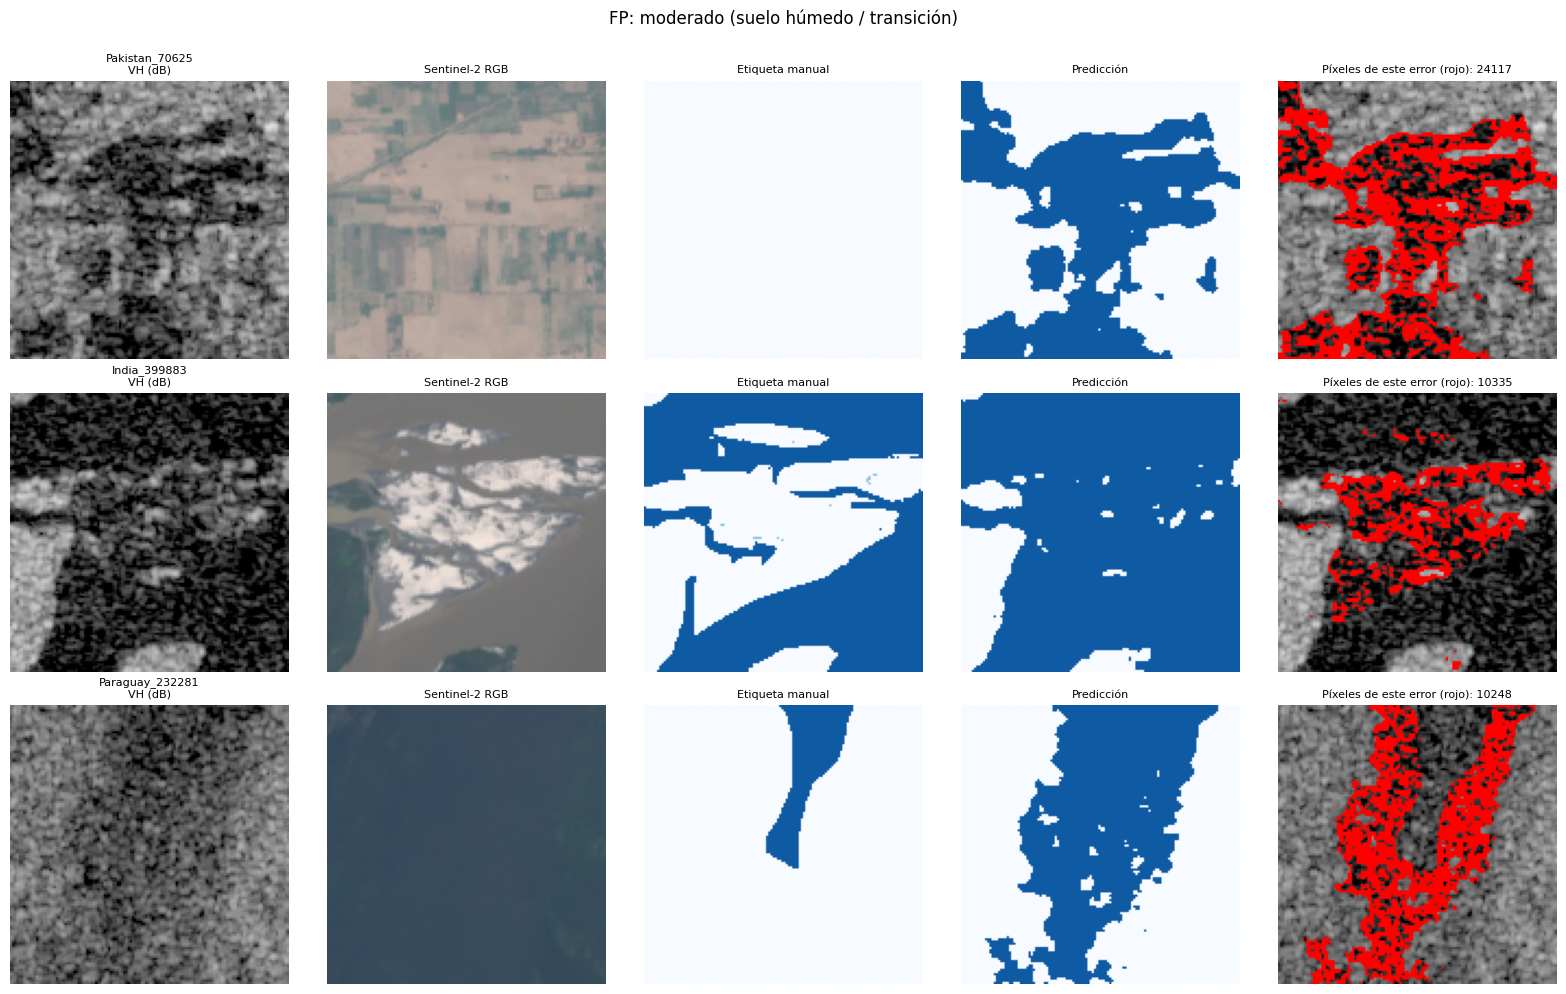

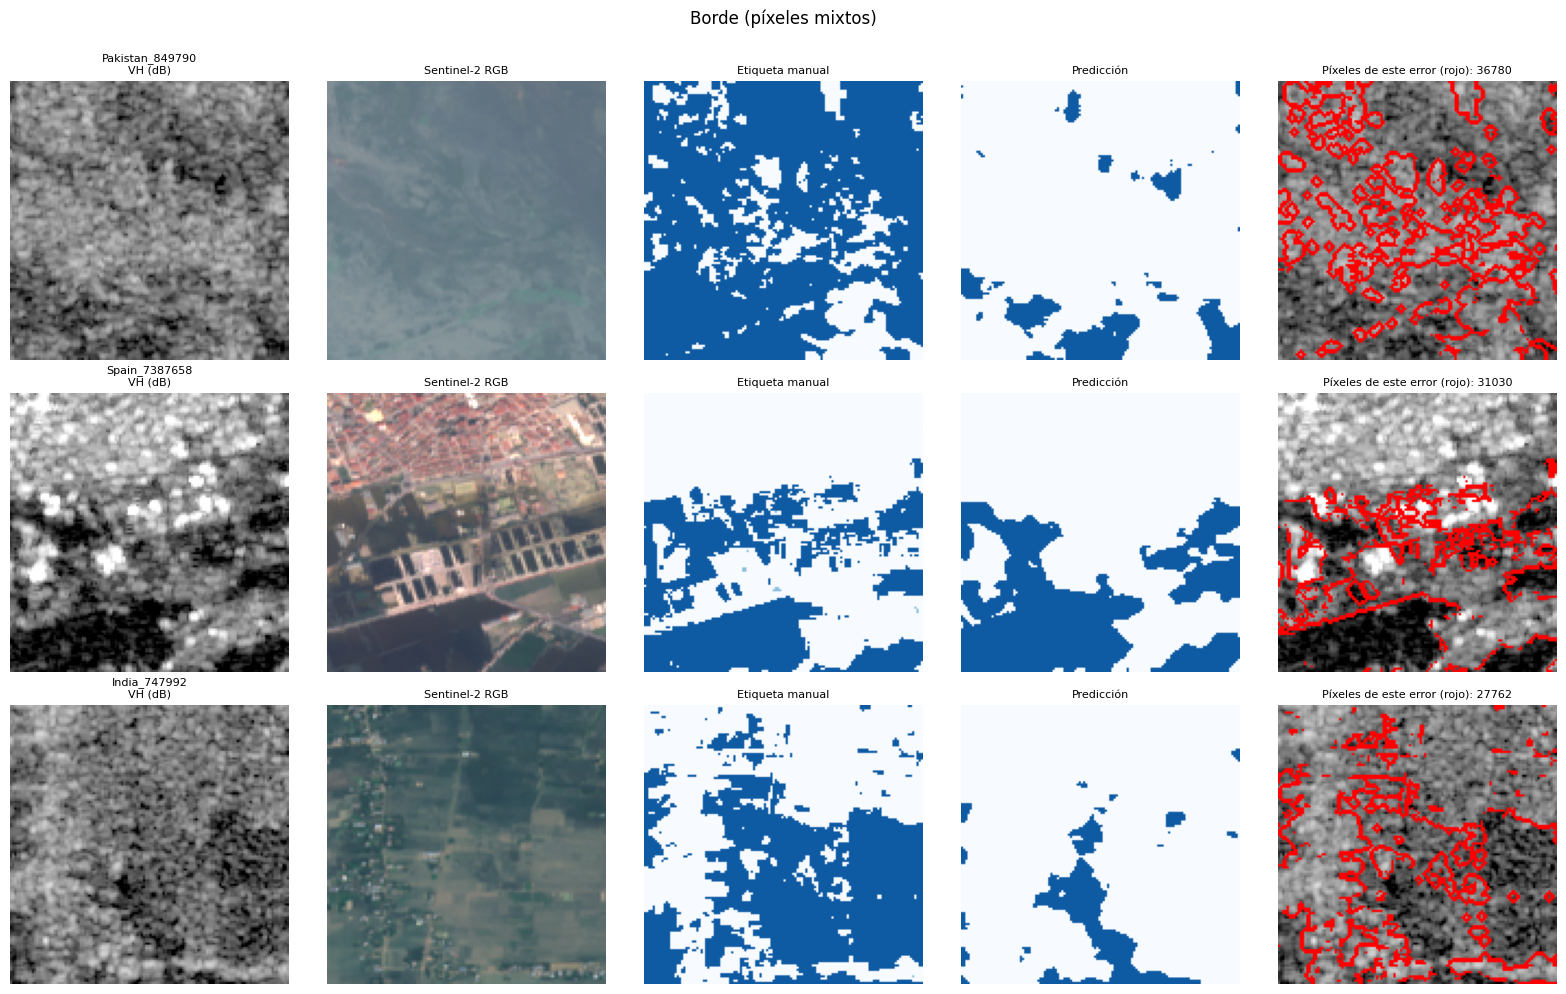

In [ ]:
def zoom_window(mask, w=128):
    dens = ndimage.uniform_filter(mask.astype(np.float32), size=64, mode='constant'); i, j = np.unravel_index(dens.argmax(), dens.shape)
    i0, j0 = int(np.clip(i - w // 2, 0, 512 - w)), int(np.clip(j - w // 2, 0, 512 - w)); return slice(i0, i0 + w), slice(j0, j0 + w)

def show_examples(cat_i, k=3):
    top = cnt.sort_values(CATS[cat_i], ascending=False).head(k); top = top[top[CATS[cat_i]] > 0]
    if top.empty: print('Sin ejemplos para:', CATS[cat_i]); return
    fig, ax = plt.subplots(len(top), 5, figsize=(16, 3.3 * len(top)), squeeze=False)
    for r, (_, row) in enumerate(top.iterrows()):
        ds, pr = (ds_test, probs_test) if row.split == 'test' else (ds_bol, probs_bol)
        s1, y, s2 = ds.cache[row.idx]; pred = pr[row.idx].astype(np.float32) > THR
        m = categorize(s1, y, pred)[0][cat_i]; sl = zoom_window(m)
        vh = s1[1][sl].astype(np.float32); ax[r, 0].imshow(vh, cmap='gray', vmin=-30, vmax=-5); ax[r, 0].set_title(f'{row.id}\nVH (dB)', fontsize=8)
        if s2 is not None: ax[r, 1].imshow(np.clip(s2[[2, 1, 0]][:, sl[0], sl[1]].astype(np.float32).transpose(1, 2, 0) / 0.3, 0, 1)); ax[r, 1].set_title('Sentinel-2 RGB', fontsize=8)
        else: ax[r, 1].imshow(s1[0][sl].astype(np.float32), cmap='gray', vmin=-25, vmax=0); ax[r, 1].set_title('VV (dB)', fontsize=8)
        ax[r, 2].imshow(np.where(y[sl] == 255, .5, y[sl]), cmap='Blues', vmin=0, vmax=1.2); ax[r, 2].set_title('Etiqueta manual', fontsize=8)
        ax[r, 3].imshow(pred[sl], cmap='Blues', vmin=0, vmax=1.2); ax[r, 3].set_title('Predicción', fontsize=8)
        base = np.dstack([np.clip((vh + 30) / 25, 0, 1)] * 3); ov = base.copy(); ov[m[sl]] = [1, 0, 0]; ax[r, 4].imshow(ov); ax[r, 4].set_title(f'Píxeles de este error (rojo): {int(m.sum())}', fontsize=8)
        for a in ax[r]: a.axis('off')
    fig.suptitle(CATS[cat_i], fontsize=12, y=1.0); plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fallos_{cat_i}.png', dpi=130, bbox_inches='tight'); plt.show()

for ci in [1, 3, 4, 0]: show_examples(ci)

**Qué escribir por cada tipo de error (≥ 3):** (i) qué se ve en la figura (VH, S2, etiqueta vs predicción), (ii) el mecanismo físico del SAR que lo explica (doble rebote en zonas urbanas/forestales inundadas → brillo alto → FN; sombra/superficies especulares → oscuro como el agua → FP; suelo húmedo → retrodispersión intermedia → confusión), (iii) la evidencia numérica de la tabla de tipos de error, (iv) una mitigación (DEM/HAND para sombra, ángulo de incidencia como canal, polarimetría/coherencia, fusión con S2, umbral de decisión). Si algún ejemplo no coincide con la regla heurística, **dilo**: las reglas son aproximaciones.

## §9. Bono: fusión SAR + Sentinel-2 (entregable 6)
Se estiman chips **libres de nubes** (heurística azul brillante/cirros, ya que el dataset no trae QA) y se comparan, con **idéntico protocolo** (mismos chips de entrenamiento, pasos y semilla): **solo-SAR (2 canales)** vs **SAR+S2 (VV, VH + B2,B3,B4,B8,B11,B12 = 8 canales)**.

In [ ]:
import copy
def subset_ds(ds, idxs, **kw):
    s = copy.copy(ds); s.items = [ds.items[i] for i in idxs]; s.cache = [ds.cache[i] for i in idxs]
    for k, v in kw.items(): setattr(s, k, v)
    return s
def cloudfree_idx(ds, thr=0.02): return [i for i in range(len(ds)) if ds.cache[i][2] is not None and cloud_fraction(ds.cache[i][2]) < thr]

def run_bonus():
    SETS = [('train', ds_train), ('valid', ds_valid), ('test', ds_test), ('bolivia', ds_bol)]
    for thr in [0.02, 0.05, 0.10, 0.20]:   # relaja el umbral si hay muy pocos chips despejados
        cf = {n: cloudfree_idx(d, thr) for n, d in SETS}
        if len(cf['train']) >= 20 and len(cf['valid']) >= 5 and len(cf['test']) >= 5: break
    print(f'Umbral de nubosidad usado: {thr} ->', {k: len(v) for k, v in cf.items()}, 'chips libres de nubes')
    if len(cf['train']) < 8 or len(cf['valid']) < 2 or len(cf['test']) < 2:
        print('Demasiado pocos chips libres de nubes: bono omitido (revisa la heurística cloud_fraction).'); return None
    if len(cf['train']) < 20: print('Aviso: pocos chips; interpreta con cautela.')
    ds_sar = {n: subset_ds(d, cf[n]) for n, d in SETS}; ds_sar['train'].train = True
    kw = dict(use_s2=True, s2_stats=compute_s2_stats(ds_train))
    ds_fus = {n: subset_ds(d, cf[n], **kw) for n, d in SETS}; ds_fus['train'].train = True
    bonus = []
    for name, dsets, in_ch in [('Solo SAR (2 canales)', ds_sar, 2), ('SAR + S2 (8 canales)', ds_fus, 8)]:
        for seed in CFG['SEEDS']:
            set_seed(seed); mdl = build_model(in_ch=in_ch, **FINAL_ARCH)
            mdl, _, best = train_model(mdl, dsets['train'], CFG['ITERS'], 'bce_dice', CFG['LR'], dsets['valid'], tag=f'bono-{in_ch}ch')
            row = dict(modelo=name, seed=seed, val_iou=best)
            for nm in ['test', 'bolivia']:
                if len(dsets[nm]):
                    r = evaluate_ds(mdl, dsets[nm]); row.update({f'{nm}_iou': r['iou'], f'{nm}_f1': r['f1'], f'{nm}_precision': r['precision'], f'{nm}_recall': r['recall']})
            bonus.append(row)
    bdf = pd.DataFrame(bonus); g = bdf.groupby('modelo', sort=False).mean(numeric_only=True)
    display(g.round(4)); bdf.to_csv(f'{OUT_DIR}/bono_fusion.csv', index=False)
    print(f"ΔIoU test (SAR+S2 − SAR) = {g['test_iou'].iloc[1] - g['test_iou'].iloc[0]:+.4f}  (pocos chips y pocas semillas: interpretar con cautela)")
    return bdf

if CFG['DOWNLOAD_S2']: bonus_df = run_bonus()
else: print('DOWNLOAD_S2=False: bono omitido.')

Umbral de nubosidad usado: 0.02 -> {'train': 130, 'valid': 42, 'test': 52, 'bolivia': 6} chips libres de nubes


bono-2ch:   0%|          | 0/1500 [00:00<?, ?it/s]

bono-8ch:   0%|          | 0/1500 [00:00<?, ?it/s]

,seed,val_iou,test_iou,test_f1,test_precision,test_recall,bolivia_iou,bolivia_f1,bolivia_precision,bolivia_recall
modelo,,,,,,,,,,
Solo SAR (2 canales),0.0,0.6636,0.6266,0.7705,0.7982,0.7445,0.7819,0.8776,0.8966,0.8594
SAR + S2 (8 canales),0.0,0.8594,0.8647,0.9275,0.9164,0.9388,0.8941,0.9441,0.9436,0.9445


ΔIoU test (SAR+S2 − SAR) = +0.2381  (pocos chips y pocas semillas: interpretar con cautela)


## §10. Cierre: exportar resultados
Descarga tablas, figuras y el checkpoint del modelo final para incluirlos en tu informe.

In [ ]:
import shutil
shutil.make_archive('/content/resultados_pregunta2', 'zip', OUT_DIR)
print(os.listdir(OUT_DIR))
try:
    from google.colab import files; files.download('/content/resultados_pregunta2.zip')
except Exception: print('Zip en /content/resultados_pregunta2.zip')

['fallos_1.png', 'brecha_bolivia.csv', 'fallos_3.png', 'bono_fusion.csv', 'h1_histogramas.png', 'fallos_0.png', 'umbral_validacion.png', 'fallos_4.png', 'cm_test.png', 'ablacion_resultados.csv', 'cm_test_vs_bolivia.png', 'modelo_final.pt', 'ablacion_barras.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>